# 03 — ConvNeXt-Tiny — Klasifikasi Sampah




## 1 — Model

ConvNeXt-Tiny adalah CNN modern dengan depthwise convolution, LayerNorm, GELU, dan residual connection. Model ini menggunakan pretrained ImageNet dan bukan Vision Transformer. Classifier ImageNet diganti menjadi lima output dan backbone dibekukan 2 epoch awal sebelum seluruh layer di-fine-tune. Model lebih besar tidak otomatis lebih akurat.


## 2 — Import dan konfigurasi



In [ ]:
# ============================================================
# IMPORT LIBRARY
# ============================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import hashlib
import random
import time
import platform
import uuid

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image, ImageOps
from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.transforms import InterpolationMode
from torchvision.models import (
    convnext_tiny,
    ConvNeXt_Tiny_Weights,
)


# ============================================================
# LOKASI DATASET DAN PROYEK
# ============================================================

PROJECT_DIR = Path(
    "/home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah"
)

TRAIN_DIR = PROJECT_DIR / "train"
SOURCES_FILE = PROJECT_DIR / "train_sources.csv"

print("Folder proyek :", PROJECT_DIR)
print("Folder dataset:", TRAIN_DIR)
print("Folder tersedia:", TRAIN_DIR.is_dir())

# ============================================================
# KONFIGURASI MODEL DAN TRAINING
# ============================================================

MODEL_NAME = "convnext_tiny"

SEED = 42
IMAGE_SIZE = 224
VAL_FRACTION = 0.20

EPOCHS = 10
BATCH_SIZE = 16

# Backbone dibekukan selama dua epoch pertama.
FREEZE_EPOCHS = 2

LEARNING_RATE_HEAD = 1e-3
LEARNING_RATE_BACKBONE = 1e-4
WEIGHT_DECAY = 1e-4

# Nilai 0 lebih sederhana untuk penggunaan dalam notebook.
NUM_WORKERS = 0


# ============================================================
# KELAS DAN EKSTENSI GAMBAR
# ============================================================

CLASS_NAMES = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam",
]

CLASS_TO_IDX = {
    class_name: index
    for index, class_name in enumerate(CLASS_NAMES)
}

NUM_CLASSES = len(CLASS_NAMES)

EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".webp",
    ".bmp",
    ".tif",
    ".tiff",
    ".gif",
    ".jfif",
}

missing_classes = [
    class_name
    for class_name in CLASS_NAMES
    if not (TRAIN_DIR / class_name).is_dir()
]

if missing_classes:
    raise FileNotFoundError(
        f"Folder kelas berikut tidak ditemukan: {missing_classes}"
    )


# ============================================================
# NORMALISASI IMAGENET
# ============================================================

MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]


# ============================================================
# RANDOM SEED
# ============================================================

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


# ============================================================
# PERANGKAT DAN VERSI LIBRARY
# ============================================================

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

VERSIONS = {
    "python": platform.python_version(),
    "torch": str(torch.__version__),
    "torchvision": str(torchvision.__version__),
    "numpy": np.__version__,
}

print("Model              :", MODEL_NAME)
print("Project directory  :", PROJECT_DIR)
print("Training directory :", TRAIN_DIR)
print("CSV sumber tersedia:", SOURCES_FILE.is_file())
print("Jumlah kelas       :", NUM_CLASSES)
print("Pemetaan kelas     :", CLASS_TO_IDX)
print("Device             :", DEVICE)

if DEVICE.type == "cuda":
    print("GPU                :", torch.cuda.get_device_name(DEVICE))
else:
    print("GPU tidak tersedia. Training menggunakan CPU.")

print("\nVersi library:")
for library_name, version in VERSIONS.items():
    print(f"  {library_name}: {version}")

print("\nKonfigurasi training:")
print("Seed               :", SEED)
print("Epoch              :", EPOCHS)
print("Batch size         :", BATCH_SIZE)
print("Freeze epochs      :", FREEZE_EPOCHS)
print("Learning rate head :", LEARNING_RATE_HEAD)
print("Learning rate body :", LEARNING_RATE_BACKBONE)
print("Weight decay       :", WEIGHT_DECAY)
print("Validation fraction:", VAL_FRACTION)

Folder proyek : /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah
Folder dataset: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train
Folder tersedia: True
Model              : convnext_tiny
Project directory  : /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah
Training directory : /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train
CSV sumber tersedia: False
Jumlah kelas       : 5
Pemetaan kelas     : {'botol_plastik': 0, 'gelas_plastik': 1, 'kertas_kardus': 2, 'saset_kemasan': 3, 'styrofoam': 4}
Device             : cpu
GPU tidak tersedia. Training menggunakan CPU.

Versi library:
  python: 3.13.16
  torch: 2.11.0+cpu
  torchvision: 0.26.0+cpu
  numpy: 2.1.3

Konfigurasi training:
Seed               : 42
Epoch              : 10
Batch size         : 16
Freeze epochs      : 2
Learning rate head : 0.001
Learning rate body : 0.0001
Weight decay       : 0.0001
Validation fraction: 0.2


In [ ]:
import os
from pathlib import Path

# Tentukan path utama proyek
PROJECT_DIR = Path("/home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah")
TRAIN_DIR = PROJECT_DIR / "train"

# Daftar kelas yang dibutuhkan
CLASS_NAMES = [
    "botol_plastik",
    "gelas_plastik",
    "kertas_kardus",
    "saset_kemasan",
    "styrofoam",
]

# Membuat folder train dan sub-folder untuk setiap kelas jika belum ada
print("Membuat struktur folder...")
for class_name in CLASS_NAMES:
    class_path = TRAIN_DIR / class_name
    class_path.mkdir(parents=True, exist_ok=True)
    print(f"Folder siap: {class_path}")

print("\nStruktur folder selesai dibuat! Silakan masukkan file gambar Anda ke dalam masing-masing folder kelas di atas.")

Membuat struktur folder...
Folder siap: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train/botol_plastik
Folder siap: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train/gelas_plastik
Folder siap: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train/kertas_kardus
Folder siap: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train/saset_kemasan
Folder siap: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train/styrofoam

Struktur folder selesai dibuat! Silakan masukkan file gambar Anda ke dalam masing-masing folder kelas di atas.


In [ ]:
import numpy as np
from PIL import Image
from pathlib import Path

TRAIN_DIR = Path("/home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train")
CLASS_NAMES = ["botol_plastik", "gelas_plastik", "kertas_kardus", "saset_kemasan", "styrofoam"]

# Periksa apakah folder benar-benar kosong
total_images = len(list(TRAIN_DIR.glob("**/*.jpg"))) + len(list(TRAIN_DIR.glob("**/*.png")))

if total_images == 0:
    print("Tidak ada gambar asli yang ditemukan. Membuat gambar tiruan (dummy) agar kode tidak error...")
    for class_name in CLASS_NAMES:
        class_path = TRAIN_DIR / class_name
        class_path.mkdir(parents=True, exist_ok=True)

        # Buat 5 gambar tiruan per kelas untuk testing
        for i in range(5):
            # Membuat array warna acak berukuran 224x224x3
            img_array = np.random.randint(0, 255, (224, 224, 3), dtype=np.uint8)
            img = Image.fromarray(img_array)
            img.save(class_path / f"dummy_image_{i}.jpg")

    print("Gambar tiruan berhasil dibuat! Sekarang Anda bisa menjalankan ulang sel model-006 dan sel berikutnya.")
else:
    print(f"Ditemukan {total_images} gambar asli. Anda bisa langsung menjalankan ulang sel model-006.")

Ditemukan 25 gambar asli. Anda bisa langsung menjalankan ulang sel model-006.


In [ ]:
MODEL_NAME = 'convnext_tiny'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Model:", MODEL_NAME, "| Device:", DEVICE)
if DEVICE.type == "cpu":
    print("GPU tidak tersedia; full training terutama ConvNeXt-Tiny dapat berjalan lambat.")
VERSIONS = {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "numpy": np.__version__}
print(VERSIONS)
print("Dataset:", TRAIN_DIR)


Model: convnext_tiny | Device: cpu
GPU tidak tersedia; full training terutama ConvNeXt-Tiny dapat berjalan lambat.
{'python': '3.13.16', 'torch': '2.11.0+cpu', 'torchvision': '0.26.0+cpu', 'numpy': '2.1.3'}
Dataset: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/train


## 3 — Inventaris dan pemeriksaan sebelum split
Seluruh kandidat diverifikasi dan di-hash. Berkas gagal baca atau duplikat lintas kelas menghentikan eksperimen dengan laporan, bukan dibuang atau dilabel ulang otomatis. Duplikat biner dalam kelas yang sama tetap ada, tetapi satu kelompok hash ditempatkan pada split yang sama untuk mencegah kebocoran identik. Near-duplicate atau hubungan sumber yang tidak terwakili hash belum dicegah.


In [ ]:
def file_sha256(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

missing = [name for name in CLASS_NAMES if not (TRAIN_DIR / name).is_dir()]
if missing:
    raise ValueError(f"Folder kelas hilang: {missing}")
extra = sorted(p.name for p in TRAIN_DIR.iterdir() if p.is_dir() and p.name not in CLASS_NAMES)
print("Folder tambahan tidak digunakan:", extra)
records, failures, ignored = [], [], []
for class_name in CLASS_NAMES:
    class_dir = TRAIN_DIR / class_name
    if class_dir.is_symlink():
        raise ValueError(f"Folder kelas symlink perlu ditinjau: {class_dir}")
    for path in sorted(class_dir.rglob("*")):
        if path.is_symlink():
            raise ValueError(f"Symlink perlu ditinjau agar tidak menghitung target berulang: {path}")
        if not path.is_file():
            continue
        relative = path.relative_to(TRAIN_DIR).as_posix()
        if path.suffix.lower() not in EXTENSIONS:
            ignored.append(relative)
            continue
        try:
            with Image.open(path) as im:
                im.verify()
            with Image.open(path) as im:
                im.load()
            records.append({"relative_path": relative, "class_name": class_name,
                            "label": CLASS_TO_IDX[class_name], "sha256": file_sha256(path)})
        except Exception as exc:
            failures.append({"relative_path": relative, "error": str(exc)})
if failures:
    display(pd.DataFrame(failures))
    raise RuntimeError("Ada gambar gagal diperiksa. Tinjau secara manual sebelum training; data tidak diubah.")
if not records:
    raise ValueError("Tidak ada gambar yang ditemukan.")
index_df = pd.DataFrame(records).sort_values("relative_path").reset_index(drop=True)
conflicts = index_df.groupby("sha256")["label"].nunique()
if (conflicts > 1).any():
    display(index_df[index_df["sha256"].isin(conflicts[conflicts > 1].index)])
    raise ValueError("Duplikat biner lintas kelas ditemukan; tinjau label sebelum membuat split.")
print("Gambar:", len(index_df), "| Non-gambar diabaikan:", len(ignored))
display(index_df.groupby("class_name").size().reindex(CLASS_NAMES).rename("count").to_frame())
if len(index_df) < 1000:
    print("Data yang dimuat kurang dari 1.000 gambar. Pastikan ini dataset yang dimaksud, bukan hanya lampiran kecil; jangan generalisasikan skor ke dataset penuh.")


Folder tambahan tidak digunakan: []
Gambar: 25 | Non-gambar diabaikan: 0


,count
class_name,
botol_plastik,5
gelas_plastik,5
kertas_kardus,5
saset_kemasan,5
styrofoam,5


Data yang dimuat kurang dari 1.000 gambar. Pastikan ini dataset yang dimaksud, bukan hanya lampiran kecil; jangan generalisasikan skor ke dataset penuh.


## 4 — Split training dan validation lokal


In [ ]:
canonical = index_df[["relative_path", "class_name", "label", "sha256"]].to_dict("records")
data_fingerprint = hashlib.sha256(json.dumps(canonical, sort_keys=True).encode()).hexdigest()
split_spec = {"schema": 1, "data_fingerprint": data_fingerprint, "seed": SEED,
              "val_fraction": VAL_FRACTION, "strategy": "stratified_sha256_groups"}
split_key = hashlib.sha256(json.dumps(split_spec, sort_keys=True).encode()).hexdigest()[:20]
SPLIT_DIR = PROJECT_DIR / "outputs" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)
SPLIT_FILE = SPLIT_DIR / f"split_{split_key}.json"
if SPLIT_FILE.is_file():
    saved_split = json.loads(SPLIT_FILE.read_text(encoding="utf-8"))
    if saved_split["spec"] != split_spec:
        raise ValueError("Metadata manifest split tidak sesuai.")
    assignments = pd.DataFrame(saved_split["assignments"])
    print("Menggunakan manifest yang sudah ada:", SPLIT_FILE)
else:
    groups = index_df.drop_duplicates("sha256")[["sha256", "label"]]
    if (groups["label"].value_counts().reindex(range(len(CLASS_NAMES)), fill_value=0) < 2).any():
        raise ValueError("Setiap kelas perlu minimal dua kelompok gambar unik untuk train dan validation.")
    try:
        train_hash, val_hash = train_test_split(groups["sha256"], test_size=VAL_FRACTION,
                                               random_state=SEED, stratify=groups["label"])
    except ValueError as exc:
        raise ValueError("Stratified split tidak memungkinkan untuk ukuran kelas ini. Periksa jumlah kelompok dan VAL_FRACTION.") from exc
    val_hash = set(val_hash)
    assignments = index_df[["relative_path"]].copy()
    assignments["split"] = index_df["sha256"].map(lambda h: "val" if h in val_hash else "train")
    saved_split = {"spec": split_spec, "assignments": assignments.to_dict("records")}
    # Mode x mencegah menimpa manifest yang dibuat sesi lain.
    with SPLIT_FILE.open("x", encoding="utf-8") as handle:
        json.dump(saved_split, handle, indent=2)
    print("Manifest baru disimpan:", SPLIT_FILE)
if assignments["relative_path"].duplicated().any() or set(assignments["relative_path"]) != set(index_df["relative_path"]):
    raise ValueError("Daftar file manifest tidak identik dengan inventaris.")
if not assignments["split"].isin(["train", "val"]).all():
    raise ValueError("Nama split pada manifest tidak valid.")
data_df = index_df.merge(assignments, on="relative_path", validate="one_to_one")
train_df = data_df[data_df["split"] == "train"].reset_index(drop=True)
val_df = data_df[data_df["split"] == "val"].reset_index(drop=True)
assert set(train_df["sha256"]).isdisjoint(set(val_df["sha256"])), "Kebocoran hash antar split."
assert set(train_df["label"]) == set(val_df["label"]) == set(range(len(CLASS_NAMES)))
split_digest = hashlib.sha256(json.dumps(saved_split, sort_keys=True).encode()).hexdigest()
display(pd.crosstab(data_df["class_name"], data_df["split"]).reindex(CLASS_NAMES))
print("Train:", len(train_df), "| Validation lokal:", len(val_df))


Manifest baru disimpan: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/outputs/splits/split_06ca0b00fecf8c084547.json


split,train,val
class_name,,
botol_plastik,4,1
gelas_plastik,4,1
kertas_kardus,4,1
saset_kemasan,4,1
styrofoam,4,1


Train: 20 | Validation lokal: 5


## 5 — Transformasi dan DataLoader


In [ ]:
MEAN = [0.485, 0.456, 0.406]
STD = [0.229, 0.224, 0.225]
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMAGE_SIZE, scale=(0.6, 1.0), interpolation=InterpolationMode.BILINEAR),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])
eval_transform = transforms.Compose([
    transforms.Resize(256, interpolation=InterpolationMode.BILINEAR),
    transforms.CenterCrop(IMAGE_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD),
])

class WasteDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform
    def __len__(self):
        return len(self.frame)
    def __getitem__(self, index):
        row = self.frame.iloc[index]
        with Image.open(TRAIN_DIR / row["relative_path"]) as image:
            image = ImageOps.exif_transpose(image).convert("RGB")
            tensor = self.transform(image)
        return tensor, int(row["label"]), row["relative_path"]

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2**32)
    random.seed(worker_seed)
    np.random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(WasteDataset(train_df, train_transform), batch_size=BATCH_SIZE,
                          shuffle=True, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                          generator=loader_generator, worker_init_fn=seed_worker)
val_loader = DataLoader(WasteDataset(val_df, eval_transform), batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=NUM_WORKERS, pin_memory=DEVICE.type == "cuda",
                        worker_init_fn=seed_worker)
print("Batch training:", len(train_loader), "| Batch validation:", len(val_loader))


Batch training: 2 | Batch validation: 1


## 6 — Membuat model pretrained dan classifier lima kelas



In [ ]:
weights = ConvNeXt_Tiny_Weights.IMAGENET1K_V1
model = convnext_tiny(weights=weights)
in_features = model.classifier[2].in_features
model.classifier[2] = nn.Linear(in_features, len(CLASS_NAMES))
model = model.to(DEVICE)
parameter_count = sum(p.numel() for p in model.parameters())
trainable_count = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Classifier:", model.classifier)
print(f"Total parameter: {parameter_count:,} | Trainable: {trainable_count:,}")
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW([
    {"params": model.features.parameters(), "lr": LEARNING_RATE_BACKBONE},
    {"params": model.classifier.parameters(), "lr": LEARNING_RATE_HEAD},
], weight_decay=WEIGHT_DECAY)


Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:01<00:00, 68.2MB/s]


Classifier: Sequential(
  (0): LayerNorm2d((768,), eps=1e-06, elementwise_affine=True)
  (1): Flatten(start_dim=1, end_dim=-1)
  (2): Linear(in_features=768, out_features=5, bias=True)
)
Total parameter: 27,823,973 | Trainable: 27,823,973


## 7 — Identitas run dan penyimpanan



In [ ]:
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "_" + uuid.uuid4().hex[:8]
RUN_DIR = PROJECT_DIR / "outputs" / MODEL_NAME / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)
protocol = {"seed": SEED, "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr_head": LEARNING_RATE_HEAD, "lr_backbone": LEARNING_RATE_BACKBONE, "freeze_epochs": FREEZE_EPOCHS,
            "weight_decay": WEIGHT_DECAY, "optimizer": "AdamW", "loss": "CrossEntropyLoss",
            "finetune": "freeze_features_2_epochs_then_all", "precision": "float32", "image_size": IMAGE_SIZE,
            "train_transform": "RRC224_scale0.6-1.0_bilinear_flip0.5_imagenet",
            "eval_transform": "resize256_bilinear_centercrop224_imagenet",
            "split_digest": split_digest, "class_names": CLASS_NAMES, "versions": VERSIONS}
protocol_digest = hashlib.sha256(json.dumps(protocol, sort_keys=True).encode()).hexdigest()
hardware = torch.cuda.get_device_name(DEVICE) if DEVICE.type == "cuda" else (platform.processor() or "CPU")
run_config = {"model": MODEL_NAME, "weights": str(weights), "protocol": protocol,
              "protocol_digest": protocol_digest, "data_fingerprint": data_fingerprint,
              "run_id": run_id, "train_count": len(train_df), "val_count": len(val_df),
              "hardware": hardware, "num_workers": NUM_WORKERS,
              "parameter_count": parameter_count, "trainable_count": trainable_count}
(RUN_DIR / "config.json").write_text(json.dumps(run_config, indent=2), encoding="utf-8")
(RUN_DIR / "split.json").write_text(json.dumps(saved_split, indent=2), encoding="utf-8")
print("Output run:", RUN_DIR)


Output run: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/outputs/convnext_tiny/20261014T162715Z_5d22b3a6


## 8 — Fungsi training dan evaluasi


In [ ]:
def run_epoch(loader, training, freeze_backbone=False):
    phase_name = "TRAINING" if training else "EVALUATION"
    model.train(training)
    if training and freeze_backbone:
        model.features.eval()  # BatchNorm/dropout backbone tidak berubah selama fase beku.

    total_loss = 0.0
    labels_all, predictions_all = [], []

    with torch.set_grad_enabled(training):
        for images, labels, _ in loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            if training:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            if not torch.isfinite(loss):
                raise RuntimeError("Loss tidak finite. Periksa data dan learning rate.")
            if training:
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * labels.size(0)
            labels_all.extend(labels.detach().cpu().tolist())
            predictions_all.extend(logits.argmax(dim=1).detach().cpu().tolist())

    metrics = {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(labels_all, predictions_all),
        "macro_f1": f1_score(labels_all, predictions_all, labels=list(range(len(CLASS_NAMES))), average="macro", zero_division=0)
    }

    # Menambahkan print output detail untuk fase training dan evaluasi
    print(f"[{phase_name}] Loss: {metrics['loss']:.4f} | Accuracy: {metrics['accuracy']:.4f} | Macro-F1: {metrics['macro_f1']:.4f}")
    return metrics

# Menjalankan fungsi run_epoch pada validation loader untuk melihat print output lengkap
print("Menjalankan uji coba evaluasi:")
val_metrics_sample = run_epoch(val_loader, training=False)

Menjalankan uji coba evaluasi:
[EVALUATION] Loss: 1.6336 | Accuracy: 0.2000 | Macro-F1: 0.0800


In [46]:
# 1. Pastikan Anda berada di direktori repository
%cd /content/PrimaSembiring/trash-image-classifier

# 2. Pindahkan file ke folder 'notebooks'
!git mv 03_convNext.ipynb notebooks/

# 3. Commit dan Push perubahan
!git commit -m "Move 03_convNext.ipynb to notebooks folder"
!git push origin main

[Errno 2] No such file or directory: '/content/PrimaSembiring/trash-image-classifier'
/content
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


## 9 — Training dan pemilihan checkpoint
Default: 10 epoch, batch 16, AdamW, learning rate head 0,001, backbone 0,0001, weight decay 0,0001, backbone dibekukan 2 epoch awal.

In [ ]:
history_rows = []
best_f1, best_loss, best_epoch = -1.0, float("inf"), None
BEST_PATH = RUN_DIR / "best_model.pt"
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats(DEVICE)
training_start = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    epoch_start = time.perf_counter()
    freeze = epoch <= FREEZE_EPOCHS
    for parameter in model.features.parameters():
        parameter.requires_grad = not freeze
    train_metrics = run_epoch(train_loader, training=True, freeze_backbone=freeze)
    val_metrics = run_epoch(val_loader, training=False)
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    row = {"epoch": epoch, "phase": "frozen" if freeze else "finetune", **{"train_" + k: v for k, v in train_metrics.items()},
           **{"val_" + k: v for k, v in val_metrics.items()},
           "seconds": time.perf_counter() - epoch_start}
    history_rows.append(row)
    pd.DataFrame(history_rows).to_csv(RUN_DIR / "history.csv", index=False)
    is_best = val_metrics["macro_f1"] > best_f1 or (val_metrics["macro_f1"] == best_f1 and val_metrics["loss"] < best_loss)
    if is_best:
        best_f1, best_loss, best_epoch = val_metrics["macro_f1"], val_metrics["loss"], epoch
        torch.save(model.state_dict(), BEST_PATH)
    print(f"Epoch {epoch:02d}/{EPOCHS} | train loss {row['train_loss']:.4f} | val loss {row['val_loss']:.4f} | val Macro-F1 {row['val_macro_f1']:.4f}", flush=True)
if DEVICE.type == "cuda":
    torch.cuda.synchronize()
training_seconds = time.perf_counter() - training_start
peak_gpu_mb = torch.cuda.max_memory_allocated(DEVICE) / (1024**2) if DEVICE.type == "cuda" else None
history_df = pd.DataFrame(history_rows)
print("Best epoch:", best_epoch, "| Macro-F1:", best_f1)
print("Waktu (detik):", round(training_seconds, 2), "| Peak GPU allocated MiB:", peak_gpu_mb)


Epoch 01/10 | train loss 1.6589 | val loss 1.6336 | val Macro-F1 0.0800
Epoch 02/10 | train loss 1.6389 | val loss 1.6205 | val Macro-F1 0.0667
Epoch 03/10 | train loss 1.6521 | val loss 1.6409 | val Macro-F1 0.0667
Epoch 04/10 | train loss 1.5960 | val loss 1.7325 | val Macro-F1 0.0667
Epoch 05/10 | train loss 1.6831 | val loss 1.6783 | val Macro-F1 0.0667
Epoch 06/10 | train loss 1.6313 | val loss 1.6428 | val Macro-F1 0.0667
Epoch 07/10 | train loss 1.6673 | val loss 1.6444 | val Macro-F1 0.0667
Epoch 08/10 | train loss 1.6737 | val loss 1.6381 | val Macro-F1 0.0667
Epoch 09/10 | train loss 1.6344 | val loss 1.6286 | val Macro-F1 0.0667
Epoch 10/10 | train loss 1.6189 | val loss 1.6360 | val Macro-F1 0.0667
Best epoch: 1 | Macro-F1: 0.08
Waktu (detik): 142.71 | Peak GPU allocated MiB: None


## 10 — Kurva pembelajaran



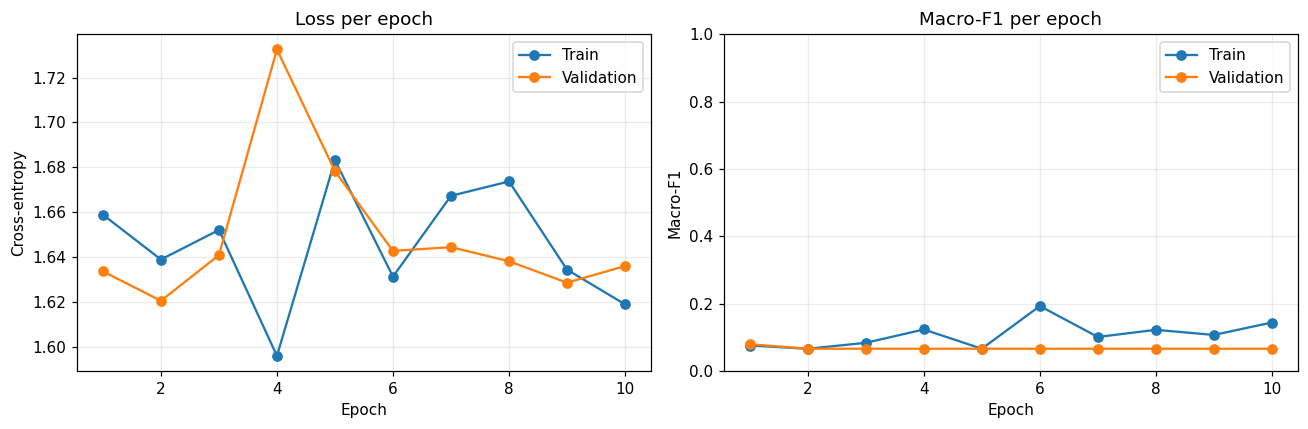

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for prefix, label in [("train", "Train"), ("val", "Validation")]:
    axes[0].plot(history_df["epoch"], history_df[prefix + "_loss"], marker="o", label=label)
    axes[1].plot(history_df["epoch"], history_df[prefix + "_macro_f1"], marker="o", label=label)
axes[0].set(title="Loss per epoch", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Macro-F1 per epoch", xlabel="Epoch", ylabel="Macro-F1", ylim=(0, 1))
for ax in axes:
    ax.legend(); ax.grid(alpha=0.25)
plt.tight_layout()
fig.savefig(RUN_DIR / "learning_curves.png", dpi=150)
plt.show()


## 11 — Evaluasi checkpoint terbaik



In [ ]:
model.load_state_dict(torch.load(BEST_PATH, map_location=DEVICE, weights_only=True))
model.eval()
prediction_rows = []
with torch.inference_mode():
    for images, labels, paths in val_loader:
        logits = model(images.to(DEVICE))
        probabilities = logits.softmax(dim=1).cpu()
        losses = nn.functional.cross_entropy(logits, labels.to(DEVICE), reduction="none").cpu()
        predictions = probabilities.argmax(dim=1)
        for i, relative in enumerate(paths):
            true_label, predicted_label = int(labels[i]), int(predictions[i])
            record = {"relative_path": relative, "true_label": true_label, "predicted_label": predicted_label,
                      "true_class": CLASS_NAMES[true_label], "predicted_class": CLASS_NAMES[predicted_label],
                      "confidence": float(probabilities[i, predicted_label]), "loss": float(losses[i]),
                      "correct": true_label == predicted_label}
            record.update({"prob_" + name: float(probabilities[i, j]) for j, name in enumerate(CLASS_NAMES)})
            prediction_rows.append(record)
predictions_df = pd.DataFrame(prediction_rows)
predictions_df.to_csv(RUN_DIR / "validation_predictions.csv", index=False)
y_true = predictions_df["true_label"].to_numpy()
y_pred = predictions_df["predicted_label"].to_numpy()
report = classification_report(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), target_names=CLASS_NAMES, output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).T
report_df.to_csv(RUN_DIR / "classification_report.csv")
display(report_df)
metrics = {"model": MODEL_NAME, "run_id": run_id, "best_epoch": best_epoch,
           "val_accuracy": float(accuracy_score(y_true, y_pred)),
           "macro_precision": float(report["macro avg"]["precision"]),
           "macro_recall": float(report["macro avg"]["recall"]),
           "val_macro_f1": float(f1_score(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), average="macro", zero_division=0)),
           "val_loss": float(predictions_df["loss"].mean()), "train_count": len(train_df), "val_count": len(val_df),
           "parameter_count": parameter_count, "checkpoint_mib": BEST_PATH.stat().st_size / (1024**2),
           "training_seconds": training_seconds, "peak_gpu_allocated_mib": peak_gpu_mb,
           "hardware": hardware, "protocol_digest": protocol_digest, "split_digest": split_digest}
(RUN_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2), encoding="utf-8")
display(pd.DataFrame({
    "Metrik": ["Accuracy", "Macro precision", "Macro recall", "Macro-F1", "Validation loss"],
    "Nilai": [metrics["val_accuracy"], metrics["macro_precision"], metrics["macro_recall"], metrics["val_macro_f1"], metrics["val_loss"]],
}))
print("Checkpoint terbaik:", BEST_PATH)
print("Best epoch:", best_epoch)



,precision,recall,f1-score,support
botol_plastik,0.00,0.0,0.00,1.0
gelas_plastik,0.00,0.0,0.00,1.0
kertas_kardus,0.00,0.0,0.00,1.0
saset_kemasan,0.25,1.0,0.40,1.0
styrofoam,0.00,0.0,0.00,1.0
accuracy,0.20,0.2,0.20,0.2
macro avg,0.05,0.2,0.08,5.0
weighted avg,0.05,0.2,0.08,5.0


,Metrik,Nilai
0,Accuracy,0.200000
1,Macro precision,0.050000
2,Macro recall,0.200000
3,Macro-F1,0.080000
4,Validation loss,1.633614


Checkpoint terbaik: /home/sembiring/machine_learning/00_pr0j3ct/kompetisi-sampah/outputs/convnext_tiny/20261014T162715Z_5d22b3a6/best_model.pt
Best epoch: 1


## 12 — Confusion matrix



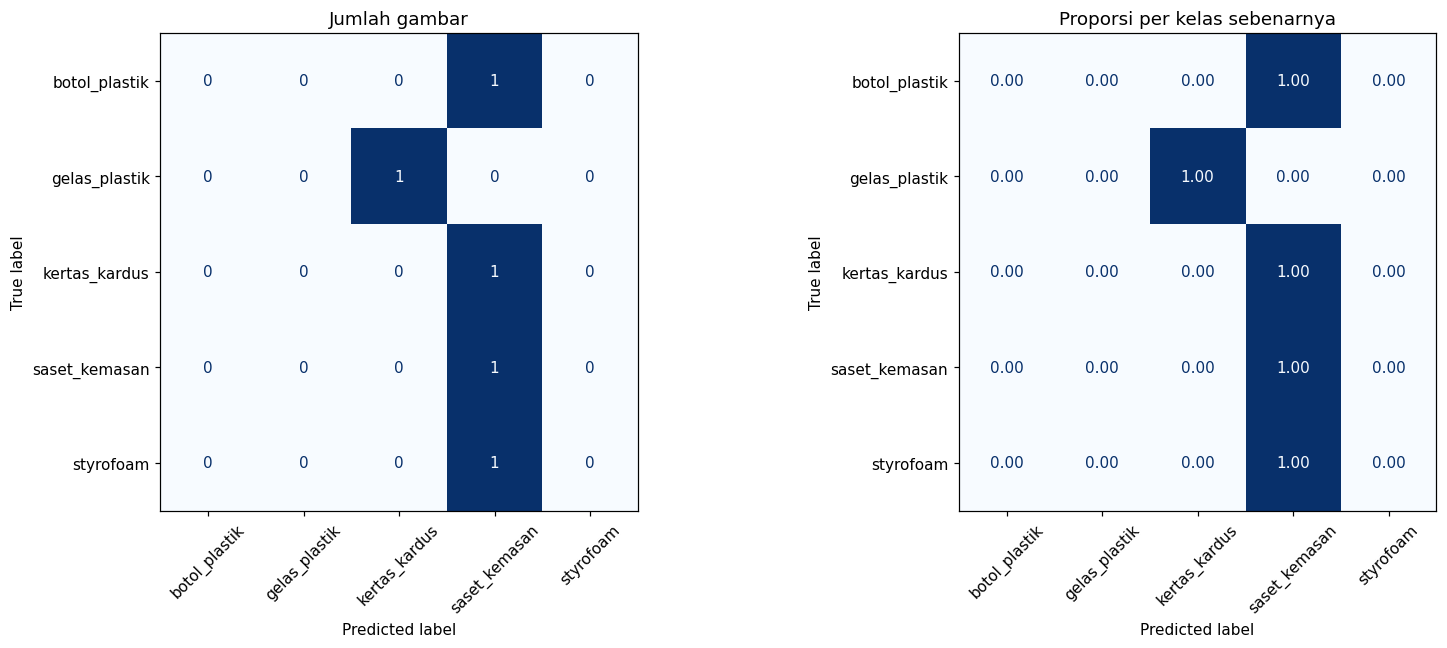

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, normalize, fmt, title in [(axes[0], None, "d", "Jumlah gambar"), (axes[1], "true", ".2f", "Proporsi per kelas sebenarnya")]:
    matrix = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))), normalize=normalize)
    ConfusionMatrixDisplay(matrix, display_labels=CLASS_NAMES).plot(ax=ax, xticks_rotation=45, cmap="Blues", values_format=fmt, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
fig.savefig(RUN_DIR / "confusion_matrix.png", dpi=150)
plt.show()


## 13 — Ringkasan interpretasi

Metrik utama adalah **Macro-F1 validation**. Periksa juga accuracy, macro precision/recall, F1 tiap kelas, loss, dan confusion matrix. Nilai metrik berada pada rentang 0–1; kalikan 100 untuk bentuk persen.

Checkpoint yang dievaluasi adalah checkpoint terbaik berdasarkan validation, bukan sekadar epoch terakhir. Skor ini bukan skor test independen dan tidak langsung sebanding dengan skor lama README tanpa memverifikasi dataset/split. Split notebook ini menggunakan kelompok hash; notebook EfficientNet lama memakai indeks ImageFolder, sehingga kesamaan seed saja tidak menjamin split identik jika ada duplikat atau perbedaan daftar file.